# 04 · Anomaly Detection (Isolation Forest)

Scores come from `python -m src.models.anomaly_detection` (saved to `results/`). This notebook only reads and visualizes them.

**Views**
- `raw`: six stats as-is, all 1,025 Pokémon
- `relative`: stat / BST, all 1,025
- `fe_relative`: stat / BST, fully evolved only (568), same setup as clustering

**Reading rule:** an anomaly means *rare in this dataset*. It does not mean wrong, broken, or strong. 'Flagged' = top 5% of scores, a reporting cutoff.

In [3]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA

from src.config import RESULTS_DIR
from src.features.preprocessing import load_pokemon, make_features, select_subset

sns.set_theme(style="whitegrid")
scores = pd.read_csv(RESULTS_DIR / "anomaly_scores.csv")
summary = json.loads((RESULTS_DIR / "anomaly_summary.json").read_text(encoding="utf-8"))
VIEWS = ["raw", "relative", "fe_relative"]
pd.DataFrame({v: summary[v] for v in VIEWS})

,raw,relative,fe_relative
n_scored,1025.000,1025.000,568.000
seed_stability_spearman,0.992,0.992,0.991
spearman_vs_max_abs_z,0.889,0.913,0.913


## 1. Score distributions

A long right tail = a few Pokémon far easier to isolate than the rest. The dashed line marks the top-5% cutoff.

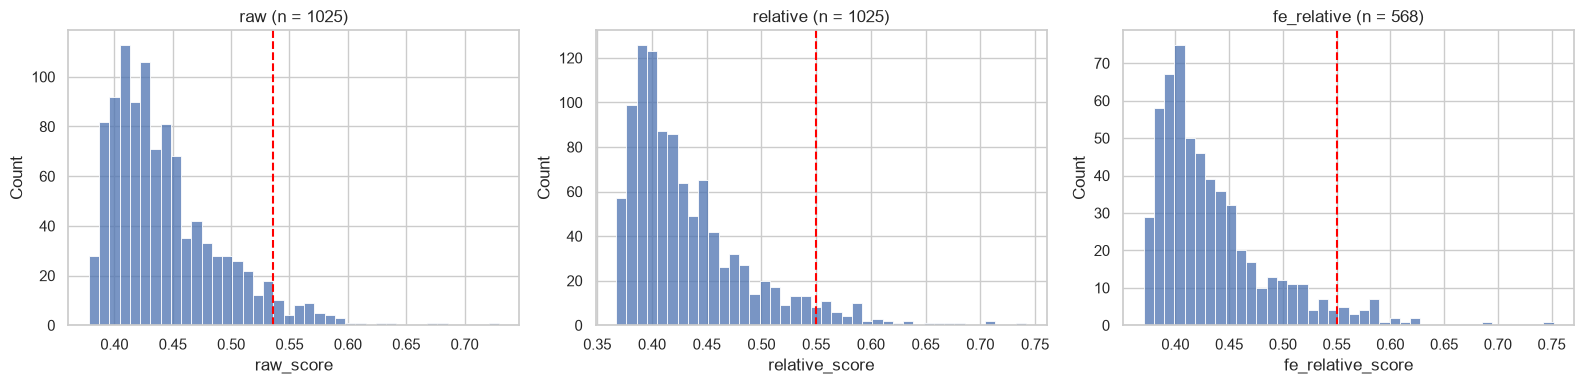

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, v in zip(axes, VIEWS):
    s = scores[f"{v}_score"].dropna()
    sns.histplot(s, bins=40, ax=ax)
    ax.axvline(s[scores[f"{v}_flagged"].eq(True)].min(), ls="--", color="red")
    ax.set_title(f"{v} (n = {len(s)})")
plt.tight_layout()

## 2. Isolation Forest vs the single-stat baseline

x = how extreme the most extreme single stat is (|z|). y = Isolation Forest score.
Points high on y but low on x are **combination anomalies**: no one stat is extreme, but the mix is rare. Those are what the forest adds over a simple rule.

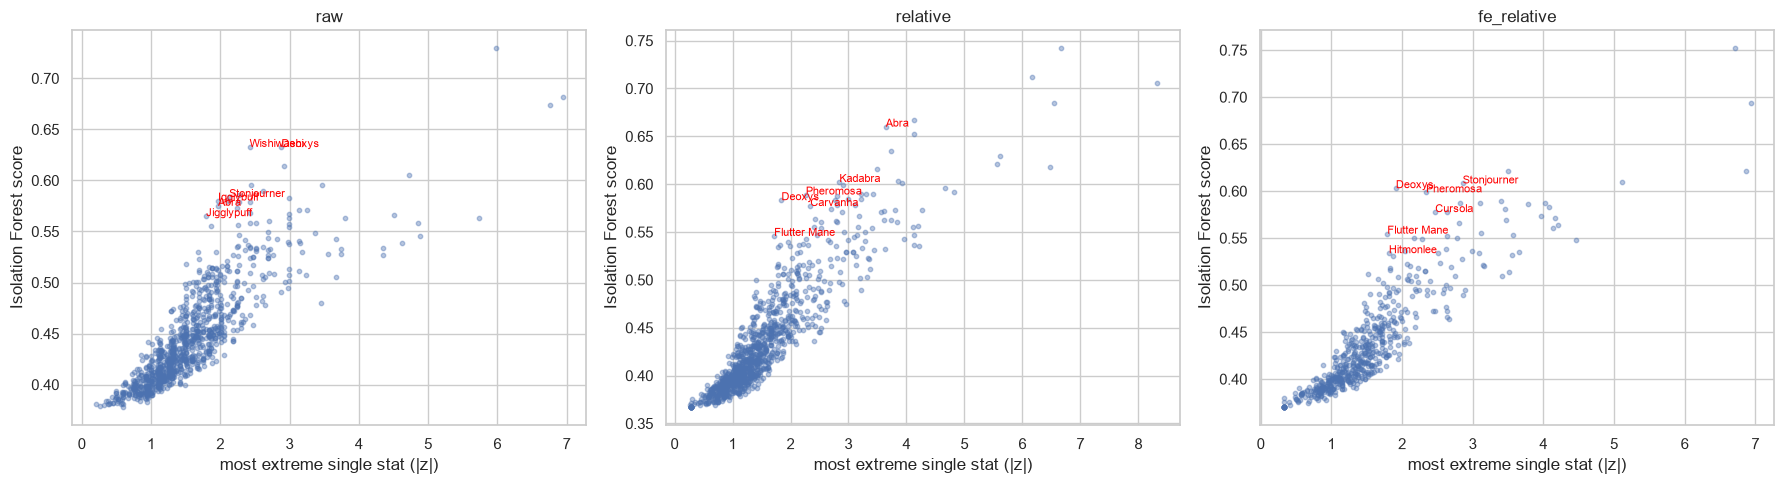

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, v in zip(axes, VIEWS):
    d = scores.dropna(subset=[f"{v}_score"])
    ax.scatter(d[f"{v}_max_abs_z"], d[f"{v}_score"], s=10, alpha=0.4)
    # residual: score higher than the baseline alone would predict
    fit = np.polyfit(d[f"{v}_max_abs_z"], d[f"{v}_score"], 1)
    resid = d[f"{v}_score"] - np.polyval(fit, d[f"{v}_max_abs_z"])
    for i in resid.nlargest(6).index:
        ax.annotate(d.loc[i, "name"], (d.loc[i, f"{v}_max_abs_z"], d.loc[i, f"{v}_score"]), fontsize=8, color="red")
    ax.set_xlabel("most extreme single stat (|z|)"); ax.set_ylabel("Isolation Forest score")
    ax.set_title(v)
plt.tight_layout()

## 3. Where do anomalies sit on the role map?

Same PCA as notebook 03 (fully evolved, relative stats). Red = flagged in `fe_relative`.

PC1 + PC2 explain 60% of the variation: anomalies can look central here and still be extreme in the other 40%.


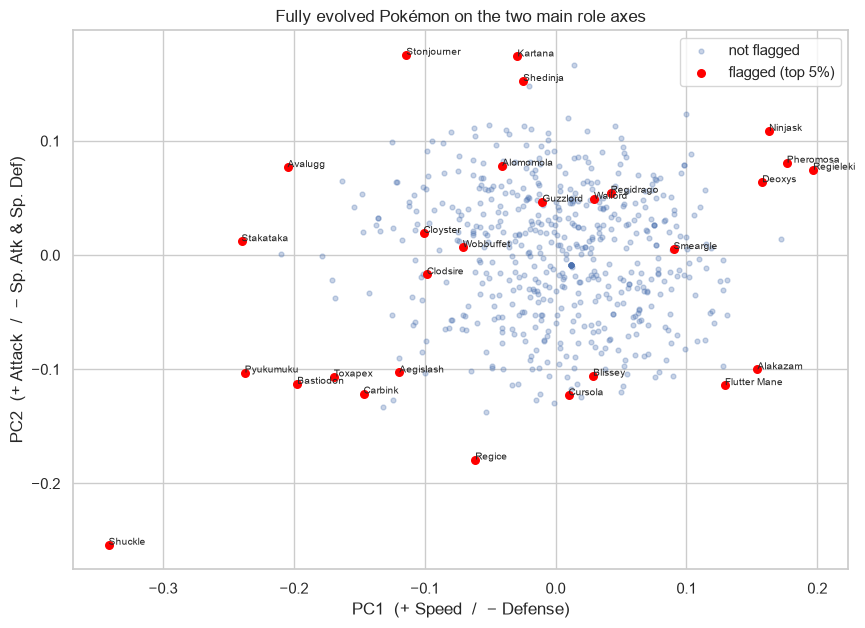

In [6]:
data = select_subset(load_pokemon(), "fully_evolved")
X, _ = make_features(data, "relative")
pca = PCA(random_state=42).fit(X)
coords = pd.DataFrame(pca.transform(X)[:, :2], columns=["PC1", "PC2"], index=data.index)
coords["name"] = data["name"]  # scores rows follow pokemon.csv order, so index lines up
coords["flagged"] = scores.loc[data.index, "fe_relative_flagged"].eq(True).to_numpy()

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(coords.loc[~coords["flagged"], "PC1"], coords.loc[~coords["flagged"], "PC2"], s=12, alpha=0.3, label="not flagged")
f = coords[coords["flagged"]]
ax.scatter(f["PC1"], f["PC2"], s=30, color="red", label="flagged (top 5%)")
for _, r in f.iterrows():
    ax.annotate(r["name"], (r["PC1"], r["PC2"]), fontsize=7)
ax.set_xlabel("PC1  (+ Speed  /  − Defense)"); ax.set_ylabel("PC2  (+ Attack  /  − Sp. Atk & Sp. Def)")
ax.legend(); ax.set_title("Fully evolved Pokémon on the two main role axes")
print(f"PC1 + PC2 explain {pca.explained_variance_ratio_[:2].sum():.0%} of the variation: anomalies can look central here and still be extreme in the other 40%.")

## 4. Are anomalies concentrated in certain generations or types?

Only ~28-51 Pokémon are flagged per view, so each generation or type has a handful. Treat differences as **hints, not findings**: a group with 3 flagged out of 40 vs 1 out of 40 is well within chance.

,flagged,n,share
type_1,,,
rock,4,33,0.121212
ghost,2,19,0.105263
ice,2,19,0.105263
bug,4,44,0.090909
poison,2,23,0.086957
psychic,3,36,0.083333
water,4,71,0.056338
dragon,1,21,0.047619


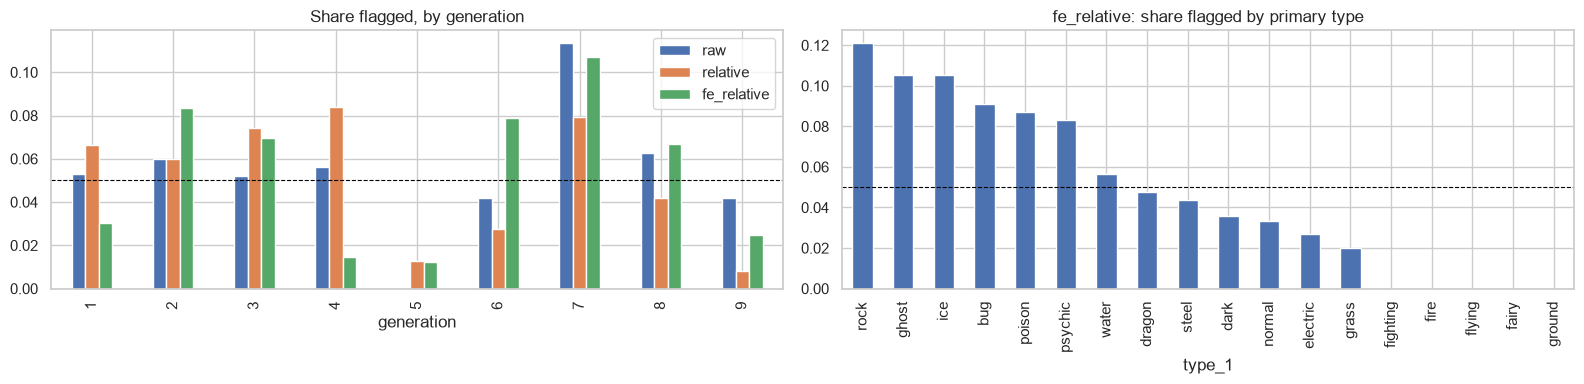

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
rates = {}
for v in VIEWS:
    d = scores.dropna(subset=[f"{v}_score"])
    rates[v] = d.groupby("generation")[f"{v}_flagged"].apply(lambda s: s.eq(True).mean())
pd.DataFrame(rates).plot.bar(ax=axes[0], title="Share flagged, by generation")
axes[0].axhline(0.05, ls="--", color="black", lw=0.8)

d = scores.dropna(subset=["fe_relative_score"])
by_type = d.groupby("type_1")["fe_relative_flagged"].agg(flagged=lambda s: s.eq(True).sum(), n="size")
by_type["share"] = by_type["flagged"] / by_type["n"]
by_type.sort_values("share", ascending=False)["share"].plot.bar(ax=axes[1], title="fe_relative: share flagged by primary type")
axes[1].axhline(0.05, ls="--", color="black", lw=0.8)
plt.tight_layout()
by_type.sort_values("share", ascending=False).head(8)

### 5.  Notes

**1. Three most interesting fully evolved anomalies**

- **Shuckle (Gen 2, Bug):** Highest anomaly score (0.752). Its stat distribution is extremely unusual, making it the strongest anomaly detected.
- **Blissey (Gen 2, Normal):** Second-highest score (0.694). Its unusual allocation of stats makes it stand out from typical fully evolved Pokémon.
- **Wobbuffet (Gen 2, Psychic):** Third-highest score (0.622). Its specialized stat distribution is also uncommon compared with the rest of the dataset.

**2. Combination anomaly**

- **Deoxys** is an interesting combination anomaly. It has a high anomaly score (0.603) despite having a maximum individual-stat z-score of only 1.91. This suggests its overall combination of stats is unusual even though no single stat is especially extreme.
- Pheromosa and Flutter Mane show similar patterns, with relatively high anomaly scores compared with their individual-stat extremes.

**3. Generation and type patterns**

- Generation 7 has the highest flagged share (10.7%), followed by Generation 2 (8.3%) and Generation 6 (7.9%). Generations 4 and 5 have the lowest rates.
- Rock has the highest flagged share by primary type (12.1%), followed by Ghost and Ice (10.5% each).
- These patterns should be treated as exploratory rather than strong conclusions. Only 28 of 568 Pokémon were flagged (4.9%), so the counts within individual generations and types are small. Differences such as 4 flagged Rock Pokémon versus 2 flagged Ghost Pokémon could easily be due to sampling variation.

**Overall takeaway:** Isolation Forest identifies Pokémon with unusual stat allocations, including Pokémon whose overall combination of stats is unusual without having one extremely unusual individual stat. These are statistical anomalies, not necessarily mistakes or objectively stronger Pokémon.